In [1]:
import re
import nltk
import numpy as np
import pandas as pd

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

from sklearn.feature_extraction.text import (
    TfidfVectorizer,
    CountVectorizer,
)

from sklearn.preprocessing import (
    MinMaxScaler,
    StandardScaler,
)

In [2]:
# Load NLTK stop words
try:
    STOP_WORDS = set(stopwords.words("english"))
except LookupError:
    nltk.download("stopwords", quiet=True)

    try:
        STOP_WORDS = set(stopwords.words("english"))
    except LookupError:
        # Fallback if NLTK data cannot be downloaded
        from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
        STOP_WORDS = set(ENGLISH_STOP_WORDS)

# Sample text dataset
texts = [
    "Machine learning is changing the world!",
    "Machine learning algorithms learn patterns from data.",
    "Natural language processing helps computers understand language.",
    "Deep learning models analyze images and text.",
    "Data science uses statistics, machine learning, and visualization.",
    "Python is a popular programming language for machine learning.",
    "Text preprocessing removes punctuation and common stop words.",
    "Normalization and standardization scale numerical features."
]

df = pd.DataFrame({"Text": texts})

print("Original dataset:")
print(df.to_string(index=False))

print("\nNumber of documents:", len(df))

Original dataset:
                                                              Text
                           Machine learning is changing the world!
             Machine learning algorithms learn patterns from data.
  Natural language processing helps computers understand language.
                     Deep learning models analyze images and text.
Data science uses statistics, machine learning, and visualization.
    Python is a popular programming language for machine learning.
     Text preprocessing removes punctuation and common stop words.
       Normalization and standardization scale numerical features.

Number of documents: 8


In [3]:
stemmer = PorterStemmer()

def preprocess_text(text):

    # 1. Convert to lowercase
    text = text.lower()

    # 2. Remove punctuation, digits and special characters
    text = re.sub(r"[^a-z\s]", " ", text)

    # 3. Tokenization
    tokens = text.split()

    # 4. Remove stop words
    tokens = [
        word for word in tokens
        if word not in STOP_WORDS
    ]

    # 5. Apply stemming
    tokens = [
        stemmer.stem(word)
        for word in tokens
    ]

    # Return the processed sentence
    return " ".join(tokens)


df["Processed_Text"] = df["Text"].apply(preprocess_text)

print("\nPreprocessed dataset:")
print(df.to_string(index=False))


Preprocessed dataset:
                                                              Text                                       Processed_Text
                           Machine learning is changing the world!                             machin learn chang world
             Machine learning algorithms learn patterns from data.            machin learn algorithm learn pattern data
  Natural language processing helps computers understand language. natur languag process help comput understand languag
                     Deep learning models analyze images and text.                    deep learn model analyz imag text
Data science uses statistics, machine learning, and visualization.          data scienc use statist machin learn visual
    Python is a popular programming language for machine learning.          python popular program languag machin learn
     Text preprocessing removes punctuation and common stop words.      text preprocess remov punctuat common stop word
       Normalizat

In [4]:
# Create the TF-IDF vectorizer
tfidf = TfidfVectorizer()

# Convert processed text to a numerical matrix
X_tfidf = tfidf.fit_transform(df["Processed_Text"])

# Extract vocabulary
feature_names = tfidf.get_feature_names_out()

# Convert sparse matrix into a DataFrame for display
tfidf_df = pd.DataFrame(
    X_tfidf.toarray(),
    columns=feature_names,
    index=[f"D{i+1}" for i in range(len(df))]
)

print("\nTF-IDF feature matrix:")
print(tfidf_df.round(3).to_string())

print("\nTF-IDF matrix shape:", X_tfidf.shape)
print("Number of documents:", X_tfidf.shape[0])
print("Number of features:", X_tfidf.shape[1])


TF-IDF feature matrix:
    algorithm  analyz  chang  common  comput   data   deep  featur   help   imag  languag  learn  machin  model  natur  normal  numer  pattern  popular  preprocess  process  program  punctuat  python  remov  scale  scienc  standard  statist   stop   text  understand   use  visual   word  world
D1      0.000   0.000  0.607   0.000   0.000  0.000  0.000   0.000  0.000  0.000    0.000  0.341   0.385  0.000  0.000   0.000  0.000    0.000    0.000       0.000    0.000    0.000     0.000   0.000  0.000  0.000    0.00     0.000     0.00  0.000  0.000       0.000  0.00    0.00  0.000  0.607
D2      0.479   0.000  0.000   0.000   0.000  0.401  0.000   0.000  0.000  0.000    0.000  0.537   0.304  0.000  0.000   0.000  0.000    0.479    0.000       0.000    0.000    0.000     0.000   0.000  0.000  0.000    0.00     0.000     0.00  0.000  0.000       0.000  0.00    0.00  0.000  0.000
D3      0.000   0.000  0.000   0.000   0.358  0.000  0.000   0.000  0.358  0.000    0.600  

In [5]:
# TF-IDF produces a sparse matrix.
# Convert to dense because this demonstration dataset is small.
X_dense = X_tfidf.toarray()

# Initialize and apply Min-Max Scaling
minmax_scaler = MinMaxScaler()

X_minmax = minmax_scaler.fit_transform(X_dense)

minmax_df = pd.DataFrame(
    X_minmax,
    columns=feature_names,
    index=[f"D{i+1}" for i in range(len(df))]
)

print("\nMin-Max Scaled Matrix:")
print(minmax_df.round(3).to_string())

print("\nMinimum value:", X_minmax.min())
print("Maximum value:", X_minmax.max())

assert X_minmax.min() >= -1e-9
assert X_minmax.max() <= 1 + 1e-9

print("Min-Max scaling test passed.")


Min-Max Scaled Matrix:
    algorithm  analyz  chang  common  comput   data  deep  featur  help  imag  languag  learn  machin  model  natur  normal  numer  pattern  popular  preprocess  process  program  punctuat  python  remov  scale  scienc  standard  statist  stop   text  understand  use  visual  word  world
D1        0.0     0.0    1.0     0.0     0.0  0.000   0.0     0.0   0.0   0.0    0.000  0.634   1.000    0.0    0.0     0.0    0.0      0.0      0.0         0.0      0.0      0.0       0.0     0.0    0.0    0.0     0.0       0.0      0.0   0.0  0.000         0.0  0.0     0.0   0.0    1.0
D2        1.0     0.0    0.0     0.0     0.0  1.000   0.0     0.0   0.0   0.0    0.000  1.000   0.789    0.0    0.0     0.0    0.0      1.0      0.0         0.0      0.0      0.0       0.0     0.0    0.0    0.0     0.0       0.0      0.0   0.0  0.000         0.0  0.0     0.0   0.0    0.0
D3        0.0     0.0    0.0     0.0     1.0  0.000   0.0     0.0   1.0   0.0    1.000  0.000   0.000    0.0 

In [6]:
# Initialize the standard scaler
standard_scaler = StandardScaler()

# Apply standardization to the TF-IDF feature matrix
X_standardized = standard_scaler.fit_transform(X_dense)

standardized_df = pd.DataFrame(
    X_standardized,
    columns=feature_names,
    index=[f"D{i+1}" for i in range(len(df))]
)

print("\nStandardized Matrix:")
print(standardized_df.round(3).to_string())

# Check means and standard deviations
feature_means = X_standardized.mean(axis=0)
feature_stds = X_standardized.std(axis=0)

print("\nMean of first 10 features:")
print(np.round(feature_means[:10], 3))

print("\nStandard deviation of first 10 features:")
print(np.round(feature_stds[:10], 3))

print("\nStandardization completed successfully.")


Standardized Matrix:
    algorithm  analyz  chang  common  comput   data   deep  featur   help   imag  languag  learn  machin  model  natur  normal  numer  pattern  popular  preprocess  process  program  punctuat  python  remov  scale  scienc  standard  statist   stop   text  understand    use  visual   word  world
D1     -0.378  -0.378  2.646  -0.378  -0.378 -0.576 -0.378  -0.378 -0.378 -0.378   -0.562  0.751   1.414 -0.378 -0.378  -0.378 -0.378   -0.378   -0.378      -0.378   -0.378   -0.378    -0.378  -0.378 -0.378 -0.378  -0.378    -0.378   -0.378 -0.378 -0.575      -0.378 -0.378  -0.378 -0.378  2.646
D2      2.646  -0.378 -0.378  -0.378  -0.378  1.853 -0.378  -0.378 -0.378 -0.378   -0.562  1.838   0.908 -0.378 -0.378  -0.378 -0.378    2.646   -0.378      -0.378   -0.378   -0.378    -0.378  -0.378 -0.378 -0.378  -0.378    -0.378   -0.378 -0.378 -0.575      -0.378 -0.378  -0.378 -0.378 -0.378
D3     -0.378  -0.378 -0.378  -0.378   2.646 -0.576 -0.378  -0.378  2.646 -0.378    2.140 

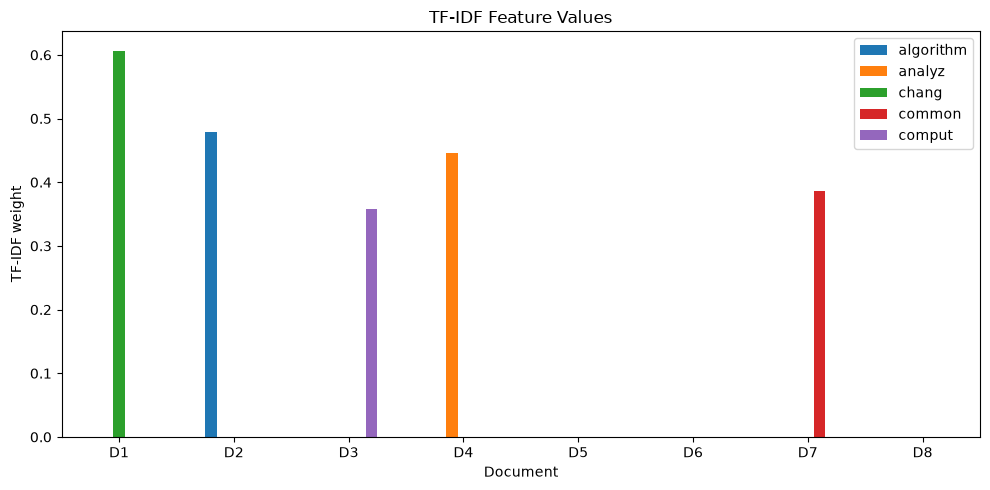

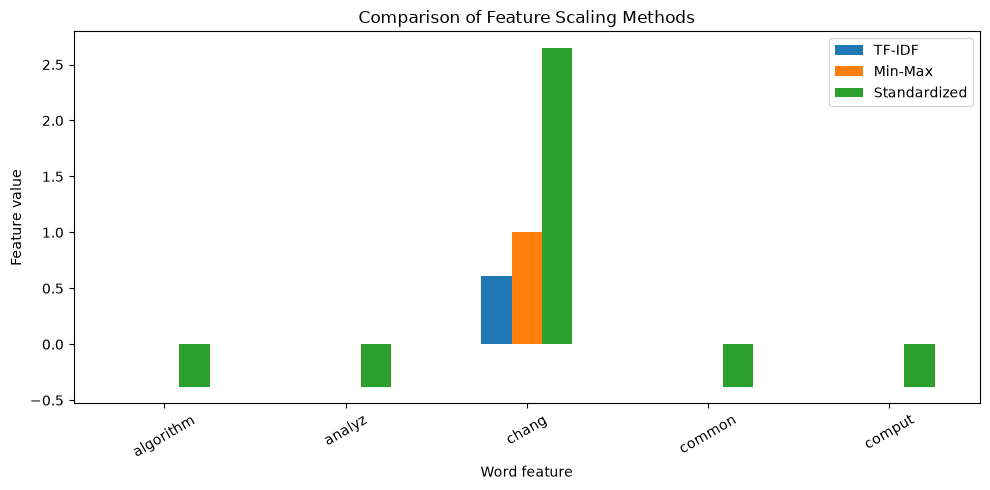

In [7]:
import matplotlib.pyplot as plt

# Plot the first 5 TF-IDF features
num_features = min(5, len(feature_names))
selected_features = list(feature_names[:num_features])

tfidf_df[selected_features].plot(
    kind="bar",
    figsize=(10, 5),
    title="TF-IDF Feature Values"
)

plt.ylabel("TF-IDF weight")
plt.xlabel("Document")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Compare the first document before and after scaling
first_doc_comparison = pd.DataFrame({
    "TF-IDF": X_dense[0, :num_features],
    "Min-Max": X_minmax[0, :num_features],
    "Standardized": X_standardized[0, :num_features]
}, index=selected_features)

first_doc_comparison.plot(
    kind="bar",
    figsize=(10, 5),
    title="Comparison of Feature Scaling Methods"
)

plt.ylabel("Feature value")
plt.xlabel("Word feature")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [8]:
count_vectorizer = CountVectorizer()

X_count = count_vectorizer.fit_transform(df["Processed_Text"])

count_df = pd.DataFrame(
    X_count.toarray(),
    columns=count_vectorizer.get_feature_names_out(),
    index=[f"D{i+1}" for i in range(len(df))]
)

print("CountVectorizer output:")
print(count_df.iloc[:, :10].to_string())

print("\nTF-IDF output:")
print(tfidf_df.iloc[:, :10].to_string())

CountVectorizer output:
    algorithm  analyz  chang  common  comput  data  deep  featur  help  imag
D1          0       0      1       0       0     0     0       0     0     0
D2          1       0      0       0       0     1     0       0     0     0
D3          0       0      0       0       1     0     0       0     1     0
D4          0       1      0       0       0     0     1       0     0     1
D5          0       0      0       0       0     1     0       0     0     0
D6          0       0      0       0       0     0     0       0     0     0
D7          0       0      0       1       0     0     0       0     0     0
D8          0       0      0       0       0     0     0       1     0     0

TF-IDF output:
    algorithm    analyz     chang    common   comput      data      deep    featur     help      imag
D1   0.000000  0.000000  0.606664  0.000000  0.00000  0.000000  0.000000  0.000000  0.00000  0.000000
D2   0.478664  0.000000  0.000000  0.000000  0.00000  0.401158 

In [14]:
from nltk.stem import WordNetLemmatizer

# Download WordNet data
nltk.download("wordnet", quiet=True)

# Initialize lemmatizer
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):

    # 1. Convert to lowercase
    text = text.lower()

    # 2. Remove punctuation and special characters
    text = re.sub(r"[^a-z\s]", " ", text)

    # 3. Tokenization
    tokens = text.split()

    # 4. Remove stop words
    tokens = [
        word for word in tokens
        if word not in STOP_WORDS
    ]

    # 5. Lemmatization (replaces stemming)
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]

    # Return processed text
    return " ".join(tokens)


# Apply preprocessing to the dataset
df["Processed_Text"] = df["Text"].apply(preprocess_text)

print(df[["Text", "Processed_Text"]].to_string(index=False))

                                                              Text                                                Processed_Text
                           Machine learning is changing the world!                               machine learning changing world
             Machine learning algorithms learn patterns from data.                 machine learning algorithm learn pattern data
  Natural language processing helps computers understand language. natural language processing help computer understand language
                     Deep learning models analyze images and text.                        deep learning model analyze image text
Data science uses statistics, machine learning, and visualization.      data science us statistic machine learning visualization
    Python is a popular programming language for machine learning.          python popular programming language machine learning
     Text preprocessing removes punctuation and common stop words.        text preprocessing remo

In [15]:
numerical_data = pd.DataFrame({
    "Hours_Studied": [1, 2, 3, 4, 5],
    "Marks": [20, 35, 50, 65, 80]
})

# Min-Max Scaling
minmax = MinMaxScaler()
minmax_result = minmax.fit_transform(numerical_data)

# Standardization
standard = StandardScaler()
standard_result = standard.fit_transform(numerical_data)

print("Original numerical data:")
print(numerical_data)

print("\nMin-Max Scaling:")
print(pd.DataFrame(
    minmax_result,
    columns=numerical_data.columns
).round(3))

print("\nStandardization:")
print(pd.DataFrame(
    standard_result,
    columns=numerical_data.columns
).round(3))

Original numerical data:
   Hours_Studied  Marks
0              1     20
1              2     35
2              3     50
3              4     65
4              5     80

Min-Max Scaling:
   Hours_Studied  Marks
0           0.00   0.00
1           0.25   0.25
2           0.50   0.50
3           0.75   0.75
4           1.00   1.00

Standardization:
   Hours_Studied  Marks
0         -1.414 -1.414
1         -0.707 -0.707
2          0.000  0.000
3          0.707  0.707
4          1.414  1.414
